# Predicción del precio mensual de la gasolina — Regresión Lineal

**Objetivo:** construir un modelo de *machine learning* que prediga el precio mensual de la gasolina (USD/galón) a partir de variables económicas, energéticas y geopolíticas, como apoyo a la toma de decisiones en política energética y estrategia comercial.

**Flujo del notebook**

1. Entrada de datos (CSV)
2. Análisis exploratorio
3. Procesamiento: valores faltantes, atípicos, normalización y selección de características
4. Modelo: Regresión Lineal (scikit-learn + statsmodels) y métricas R², MAE y MSE (partición 65 % entrenamiento / 35 % prueba)
5. Salida: predicción en USD/galón con intervalo de confianza del 95 %
6. Exportación del modelo para el aplicativo (`app_gasolina.py`, Streamlit)

## 0. Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_regression
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
SEED = 42
np.random.seed(SEED)

## 1. Entrada de datos

In [2]:
RUTA_CSV = "dataset_precio_gasolina 1 5.csv"   # ajuste la ruta si es necesario
TARGET = "Precio_Gasolina_USD_Galon"

df_raw = pd.read_csv(RUTA_CSV, parse_dates=["Fecha"])
df_raw = df_raw.sort_values("Fecha").reset_index(drop=True)
print(f"Filas: {df_raw.shape[0]}  |  Columnas: {df_raw.shape[1]}")
print(f"Periodo: {df_raw.Fecha.min():%Y-%m} a {df_raw.Fecha.max():%Y-%m}")
df_raw.head()

Filas: 72  |  Columnas: 10
Periodo: 2018-01 a 2023-12


,Fecha,Precio_Gasolina_USD_Galon,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
0,2018-01-01,8.17,73.94,3683.88,9673.0,27.45,3.84,3.54,1,18
1,2018-02-01,8.51,62.51,4404.09,9819.0,28.53,2.75,5.57,0,22
2,2018-03-01,8.17,76.66,2521.11,9254.0,28.03,3.25,2.28,0,22
3,2018-04-01,9.09,92.41,4069.86,9230.0,29.16,2.91,3.30,0,22
4,2018-05-01,8.10,60.79,3739.17,9746.0,33.63,2.79,3.88,0,18


In [3]:
df_raw.info()
df_raw.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 10 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Fecha                              72 non-null     datetime64[us]
 1   Precio_Gasolina_USD_Galon          72 non-null     float64       
 2   Precio_Petroleo_USD_Barril         72 non-null     float64       
 3   Tipo_Cambio_USD_COP                72 non-null     float64       
 4   Demanda_miles_barriles_dia         72 non-null     float64       
 5   Produccion_OPEP_millones_dia       72 non-null     float64       
 6   Inflacion_Porcentaje               72 non-null     float64       
 7   PIB_Porcentaje                     72 non-null     float64       
 8   Eventos_Geopoliticos               72 non-null     int64         
 9   Impuestos_Combustibles_Porcentaje  72 non-null     int64         
dtypes: datetime64[us](1), float64(7), int64(2)
memory u

,count,mean,min,25%,50%,75%,max,std
Fecha,72,2020-12-15 15:20:00,2018-01-01 00:00:00,2019-06-23 12:00:00,2020-12-16 12:00:00,2022-06-08 12:00:00,2023-12-01 00:00:00,NaN
Precio_Gasolina_USD_Galon,72.0,8.104444,6.56,7.4875,8.08,8.73,10.5,0.790899
Precio_Petroleo_USD_Barril,72.0,63.117778,29.73,53.2475,62.085,74.1475,98.34,16.38322
Tipo_Cambio_USD_COP,72.0,3674.238611,2521.11,3429.8975,3686.225,3889.645,4808.46,444.171734
Demanda_miles_barriles_dia,72.0,9652.069444,9176.0,9407.5,9682.5,9788.0,10679.0,270.140304
Produccion_OPEP_millones_dia,72.0,28.897778,25.0,27.5175,28.825,30.33,33.63,2.134165
Inflacion_Porcentaje,72.0,3.563333,1.76,2.8275,3.51,4.25,6.01,0.883983
PIB_Porcentaje,72.0,2.779167,-1.75,1.225,2.735,4.405,6.88,2.120914
Eventos_Geopoliticos,72.0,0.138889,0.0,0.0,0.0,0.0,1.0,0.348257
Impuestos_Combustibles_Porcentaje,72.0,22.180556,18.0,21.0,22.0,25.0,30.0,3.229819


## 2. Análisis exploratorio

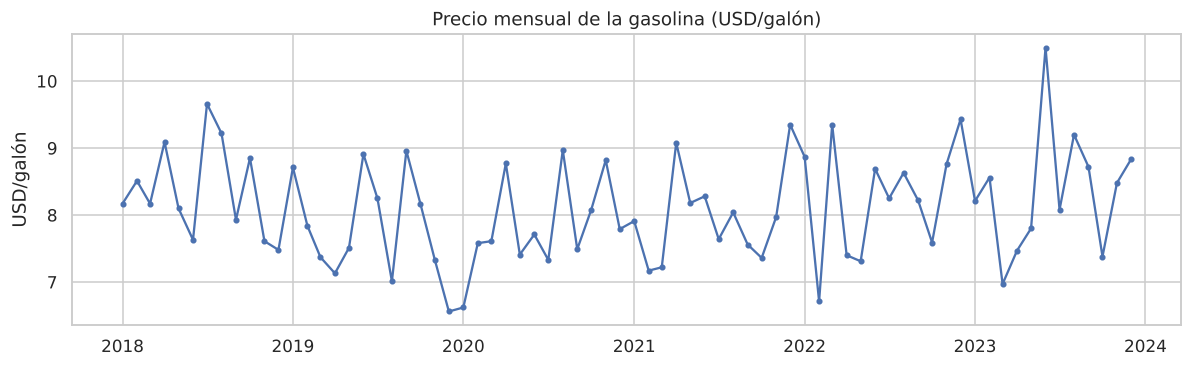

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(df_raw.Fecha, df_raw[TARGET], marker="o", ms=3)
ax.set_title("Precio mensual de la gasolina (USD/galón)")
ax.set_ylabel("USD/galón")
plt.tight_layout(); plt.show()

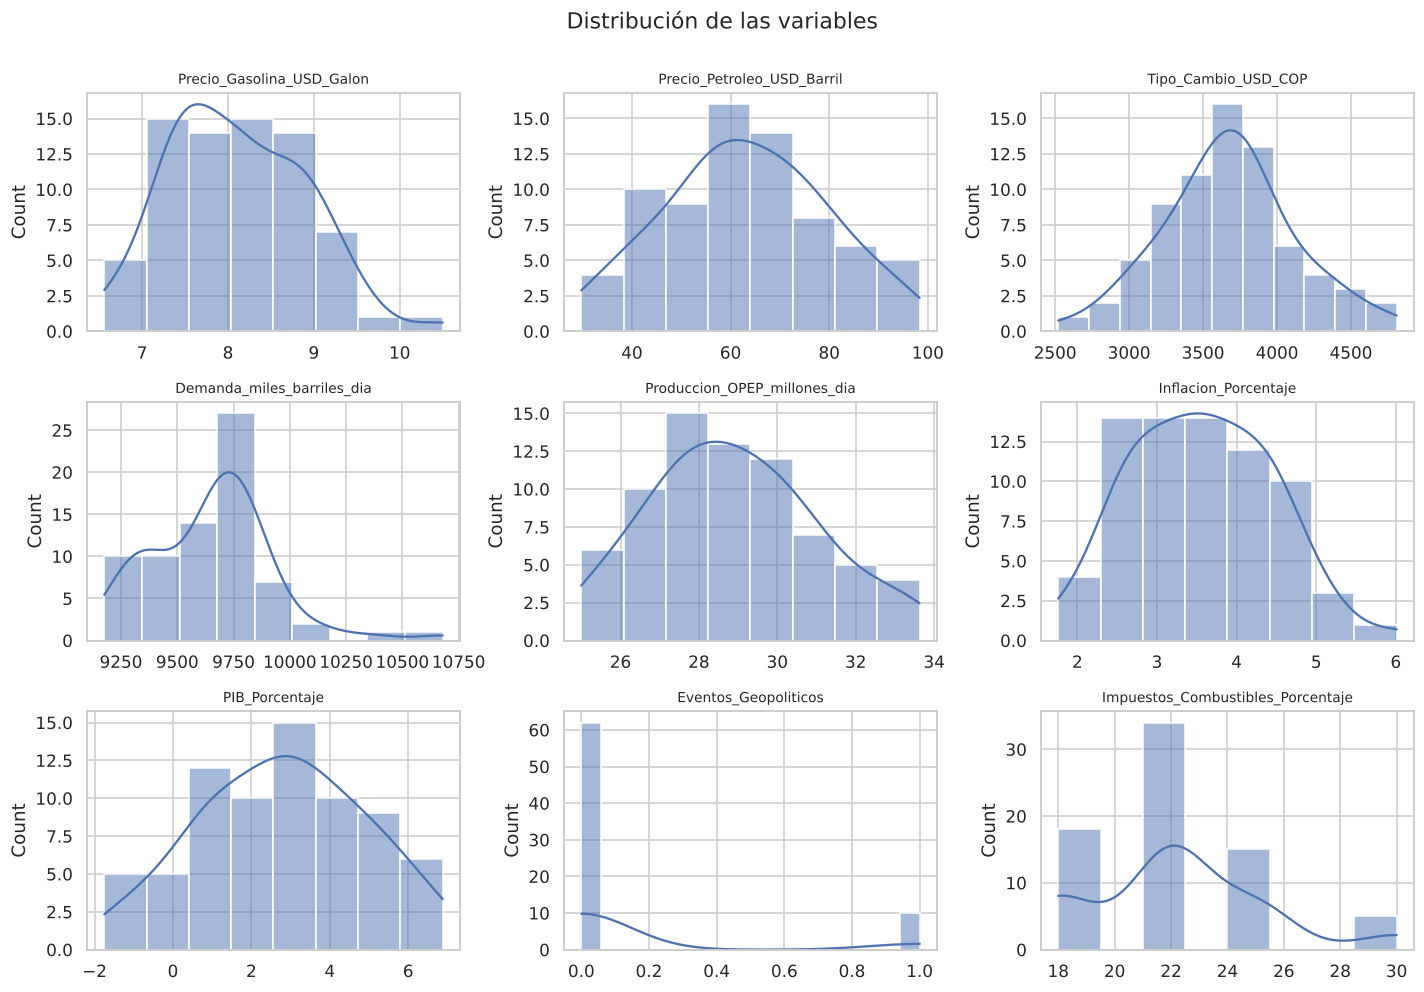

In [5]:
num_cols = df_raw.select_dtypes("number").columns
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df_raw[c], kde=True, ax=ax)
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
plt.suptitle("Distribución de las variables", y=1.0)
plt.tight_layout(); plt.show()

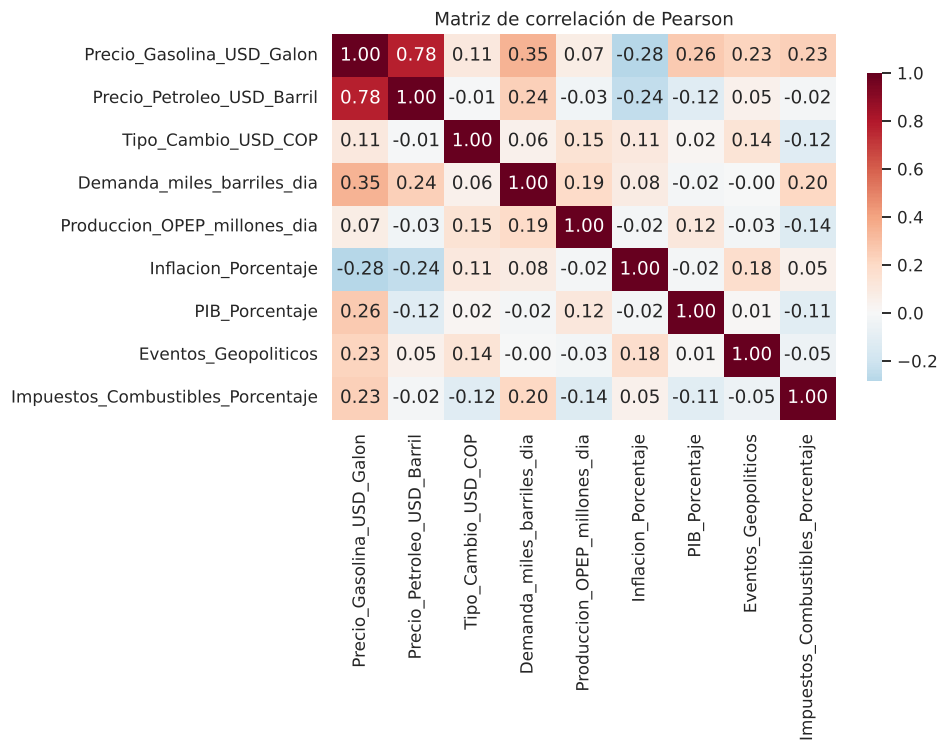

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_raw[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"shrink": .8})
plt.title("Matriz de correlación de Pearson")
plt.tight_layout(); plt.show()

## 3. Procesamiento

### 3.1 Valores faltantes y duplicados
Se revisan nulos y duplicados. Si existieran nulos, se imputan con la **mediana** (robusta a atípicos) en variables continuas y con la **moda** en variables discretas. Filas sin valor en la variable objetivo se eliminan.

In [7]:
df = df_raw.copy()
print("Valores faltantes por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=[TARGET])

DISCRETAS = ["Eventos_Geopoliticos", "Impuestos_Combustibles_Porcentaje"]
CONTINUAS = [c for c in df.select_dtypes("number").columns if c not in DISCRETAS + [TARGET]]

for c in CONTINUAS:
    df[c] = df[c].fillna(df[c].median())
for c in DISCRETAS:
    df[c] = df[c].fillna(df[c].mode()[0])

print("\nNulos tras imputación:", int(df.isna().sum().sum()))

Valores faltantes por columna:
Fecha                                0
Precio_Gasolina_USD_Galon            0
Precio_Petroleo_USD_Barril           0
Tipo_Cambio_USD_COP                  0
Demanda_miles_barriles_dia           0
Produccion_OPEP_millones_dia         0
Inflacion_Porcentaje                 0
PIB_Porcentaje                       0
Eventos_Geopoliticos                 0
Impuestos_Combustibles_Porcentaje    0

Filas duplicadas: 0

Nulos tras imputación: 0


### 3.2 Valores atípicos (método IQR)
Se detectan atípicos con el rango intercuartílico (Q1 − 1.5·IQR, Q3 + 1.5·IQR). En lugar de borrar filas (con solo 72 meses perderíamos información), se aplica **winsorización**: los valores extremos de las variables explicativas continuas se recortan a los límites. La variable objetivo **no se modifica**, para no distorsionar lo que se quiere predecir; solo se reporta.

In [8]:
def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

resumen = []
for c in CONTINUAS + [TARGET]:
    lo, hi = limites_iqr(df[c])
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    resumen.append({"variable": c, "lim_inf": round(lo, 2), "lim_sup": round(hi, 2), "n_atipicos": n})
resumen = pd.DataFrame(resumen)
resumen

,variable,lim_inf,lim_sup,n_atipicos
0,Precio_Petroleo_USD_Barril,21.90,105.50,0
1,Tipo_Cambio_USD_COP,2740.28,4579.27,3
2,Demanda_miles_barriles_dia,8836.75,10358.75,2
3,Produccion_OPEP_millones_dia,23.30,34.55,0
4,Inflacion_Porcentaje,0.69,6.38,0
5,PIB_Porcentaje,-3.55,9.18,0
6,Precio_Gasolina_USD_Galon,5.62,10.59,0


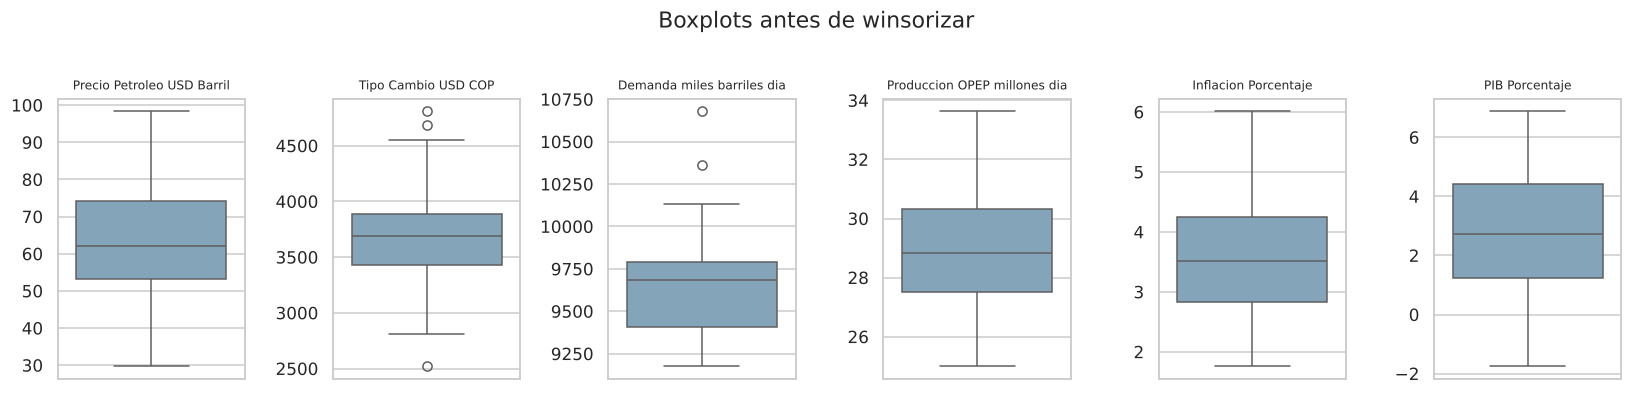

In [9]:
fig, axes = plt.subplots(1, len(CONTINUAS), figsize=(15, 3.5))
for ax, c in zip(axes, CONTINUAS):
    sns.boxplot(y=df[c], ax=ax, color="#7aa6c2")
    ax.set_title(c.replace("_", " "), fontsize=8); ax.set_ylabel("")
plt.suptitle("Boxplots antes de winsorizar", y=1.02)
plt.tight_layout(); plt.show()

In [10]:
LIMITES_CLIP = {}
for c in CONTINUAS:
    lo, hi = limites_iqr(df[c])
    LIMITES_CLIP[c] = (float(lo), float(hi))
    df[c] = df[c].clip(lo, hi)

print("Atípicos restantes en variables explicativas:",
      sum(int(((df[c] < LIMITES_CLIP[c][0]) | (df[c] > LIMITES_CLIP[c][1])).sum()) for c in CONTINUAS))

Atípicos restantes en variables explicativas: 0


### 3.3 Selección de características mediante análisis estadístico
Se combinan cuatro criterios:

1. **Correlación de Pearson** y **prueba F univariada** (`f_regression`): miden la relación de cada variable *por sí sola* con el precio. Sirven como diagnóstico inicial.
2. **Eliminación hacia atrás (backward elimination) con OLS multivariado:** se parte de todas las variables y se elimina, una a una, la de mayor p-valor mientras supere **0.05**. Este criterio evalúa cada variable *controlando por las demás*.
3. **Factor de inflación de varianza (VIF) < 5** para descartar multicolinealidad.

¿Por qué no basta con la prueba univariada? Una variable puede parecer irrelevante sola y ser significativa cuando las demás están en el modelo, porque su efecto queda "tapado" por la variación de otras (p. ej., el tipo de cambio). La selección final se hace con el criterio multivariado.

In [11]:
FEATURES_ALL = CONTINUAS + DISCRETAS
X_all, y = df[FEATURES_ALL], df[TARGET]

F, p_f = f_regression(X_all, y)
corr = [stats.pearsonr(X_all[c], y) for c in FEATURES_ALL]
tabla_sel = pd.DataFrame({
    "pearson_r": [r for r, _ in corr],
    "p_pearson": [p for _, p in corr],
    "F": F,
    "p_F": p_f,
}, index=FEATURES_ALL).sort_values("p_F")

ALPHA = 0.05
tabla_sel["signif_univariada"] = tabla_sel["p_F"] < ALPHA
tabla_sel.round(4)

,pearson_r,p_pearson,F,p_F,signif_univariada
Precio_Petroleo_USD_Barril,0.7770,0.0000,106.6528,0.0000,True
Demanda_miles_barriles_dia,0.3170,0.0067,7.8207,0.0067,True
Inflacion_Porcentaje,-0.2838,0.0157,6.1303,0.0157,True
PIB_Porcentaje,0.2633,0.0254,5.2146,0.0254,True
Impuestos_Combustibles_Porcentaje,0.2338,0.0480,4.0494,0.0480,True
Eventos_Geopoliticos,0.2273,0.0548,3.8145,0.0548,False
Tipo_Cambio_USD_COP,0.1104,0.3561,0.8630,0.3561,False
Produccion_OPEP_millones_dia,0.0731,0.5418,0.3758,0.5418,False


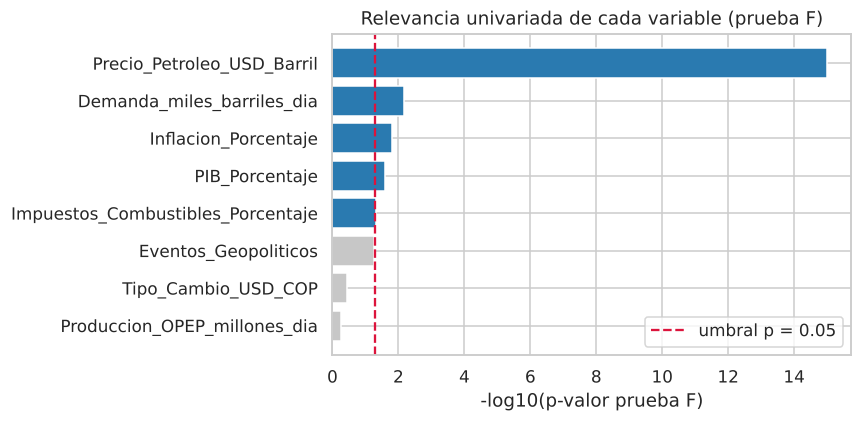

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
colores = ["#2a7ab0" if s else "#c7c7c7" for s in tabla_sel["signif_univariada"]]
ax.barh(tabla_sel.index, -np.log10(tabla_sel["p_F"]), color=colores)
ax.axvline(-np.log10(ALPHA), ls="--", c="crimson", label=f"umbral p = {ALPHA}")
ax.invert_yaxis(); ax.set_xlabel("-log10(p-valor prueba F)")
ax.set_title("Relevancia univariada de cada variable (prueba F)"); ax.legend()
plt.tight_layout(); plt.show()

In [13]:
# Eliminación hacia atrás con OLS multivariado
def backward_elimination(X, y, alpha=ALPHA):
    feats = list(X.columns)
    historial = []
    while True:
        Xs = (X[feats] - X[feats].mean()) / X[feats].std()
        modelo = sm.OLS(y, sm.add_constant(Xs)).fit()
        pv = modelo.pvalues.drop("const")
        if pv.max() <= alpha:
            return feats, modelo, historial
        peor = pv.idxmax()
        historial.append((peor, round(pv.max(), 4)))
        feats.remove(peor)

FEATURES, ols_sel, eliminadas = backward_elimination(df[FEATURES_ALL], df[TARGET])
print("Variables eliminadas (variable, p-valor):", eliminadas)

tabla_sel["p_multivariado"] = ols_sel.pvalues.reindex(tabla_sel.index)
tabla_sel["seleccionada"] = tabla_sel.index.isin(FEATURES)
display(tabla_sel[["p_F", "signif_univariada", "p_multivariado", "seleccionada"]].round(4))

# Control de multicolinealidad: se elimina iterativamente la variable de mayor VIF si supera 5
def calcular_vif(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])],
                     index=X.columns, name="VIF")

while True:
    vif = calcular_vif(df[FEATURES])
    if vif.max() < 5:
        break
    FEATURES.remove(vif.idxmax())

FEATURES_UNIV = tabla_sel.index[tabla_sel["signif_univariada"]].tolist()   # para comparar después
print("Características seleccionadas:", FEATURES)
vif.round(2).to_frame()

Variables eliminadas (variable, p-valor): [('Produccion_OPEP_millones_dia', np.float64(0.1198))]


,p_F,signif_univariada,p_multivariado,seleccionada
Precio_Petroleo_USD_Barril,0.0000,True,0.0000,True
Demanda_miles_barriles_dia,0.0067,True,0.0053,True
Inflacion_Porcentaje,0.0157,True,0.0002,True
PIB_Porcentaje,0.0254,True,0.0000,True
Impuestos_Combustibles_Porcentaje,0.0480,True,0.0000,True
Eventos_Geopoliticos,0.0548,False,0.0000,True
Tipo_Cambio_USD_COP,0.3561,False,0.0025,True
Produccion_OPEP_millones_dia,0.5418,False,NaN,False


Características seleccionadas: ['Precio_Petroleo_USD_Barril', 'Tipo_Cambio_USD_COP', 'Demanda_miles_barriles_dia', 'Inflacion_Porcentaje', 'PIB_Porcentaje', 'Eventos_Geopoliticos', 'Impuestos_Combustibles_Porcentaje']


,VIF
Precio_Petroleo_USD_Barril,1.17
Tipo_Cambio_USD_COP,1.05
Demanda_miles_barriles_dia,1.12
Inflacion_Porcentaje,1.14
PIB_Porcentaje,1.03
Eventos_Geopoliticos,1.06
Impuestos_Combustibles_Porcentaje,1.07


### 3.4 Partición 65 % / 35 % y normalización
Los datos se dividen en **65 % para entrenamiento** y **35 % para prueba** con `train_test_split` (semilla fija `random_state=42` para que el resultado sea reproducible). La prueba de Durbin-Watson de la sección 4.4 confirma que los residuos no tienen autocorrelación, por lo que una partición aleatoria es válida para estos datos.

La normalización (`StandardScaler`, media 0 y desviación 1) se ajusta **solo con el conjunto de entrenamiento** para evitar fuga de información. Esto pone en la misma escala variables como el tipo de cambio (~3.600 COP) y la inflación (~3 %), y hace comparables los coeficientes.

In [14]:
TEST_SIZE = 0.35   # 65 % entrenamiento / 35 % prueba
train, test = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, shuffle=True)
train, test = train.sort_values("Fecha"), test.sort_values("Fecha")
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(f"Entrenamiento: {len(train)} meses ({len(train)/len(df):.0%})")
print(f"Prueba:        {len(test)} meses ({len(test)/len(df):.0%})")

scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURES, index=X_test.index)
X_train_s.describe().loc[["mean", "std"]].round(3)

Entrenamiento: 46 meses (64%)
Prueba:        26 meses (36%)


,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
mean,-0.000,0.000,0.000,0.000,0.000,-0.000,-0.000
std,1.011,1.011,1.011,1.011,1.011,1.011,1.011


## 4. Modelo: Regresión Lineal

### 4.1 scikit-learn — entrenamiento y métricas

In [15]:
modelo_sk = Pipeline([("scaler", StandardScaler()), ("reg", LinearRegression())])
modelo_sk.fit(X_train, y_train)

def metricas(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mean_squared_error(y_true, y_pred)}

res = pd.DataFrame({
    "Entrenamiento": metricas(y_train, modelo_sk.predict(X_train)),
    "Prueba": metricas(y_test, modelo_sk.predict(X_test)),
}).T.round(4)
res

,R2,MAE,MSE
Entrenamiento,0.9258,0.1678,0.0459
Prueba,0.8431,0.2570,0.0956


**Interpretación de las métricas**

| Métrica | Qué mide | Ideal |
|---|---|---|
| **R²** | Fracción de la variación del precio que explica el modelo | ↑ cercano a 1 |
| **MAE** | Error absoluto medio, en USD/galón | ↓ cercano a 0 |
| **MSE** | Error cuadrático medio (USD/galón)²; penaliza más los errores grandes | ↓ cercano a 0 |

Si las métricas de prueba son parecidas a las de entrenamiento, el modelo no está sobreajustado.

In [16]:
# Validación cruzada K-Fold (5 particiones) para confirmar que el resultado no depende de una sola partición
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv = cross_validate(modelo_sk, df[FEATURES], df[TARGET], cv=kf,
                    scoring=("r2", "neg_mean_absolute_error", "neg_mean_squared_error"))
cv_res = pd.DataFrame({
    "R2": cv["test_r2"],
    "MAE": -cv["test_neg_mean_absolute_error"],
    "MSE": -cv["test_neg_mean_squared_error"],
})
cv_res.index = [f"Bloque {i+1}" for i in range(len(cv_res))]
cv_res.loc["Media"] = cv_res.mean()
cv_res.loc["Desv."] = cv_res.iloc[:-1].std()
cv_res.round(4)

,R2,MAE,MSE
Bloque 1,0.7846,0.2573,0.1119
Bloque 2,0.8907,0.2032,0.0634
Bloque 3,0.8810,0.1979,0.0655
Bloque 4,0.8908,0.2468,0.0921
Bloque 5,0.9094,0.1787,0.0444
Media,0.8713,0.2168,0.0755
Desv.,0.0495,0.0337,0.0265


In [17]:
# Comparación con un modelo base que siempre predice la media de entrenamiento
base = np.full(len(y_test), y_train.mean())
pd.DataFrame({"Regresión lineal": metricas(y_test, modelo_sk.predict(X_test)),
              "Base (media)": metricas(y_test, base)}).T.round(4)

,R2,MAE,MSE
Regresión lineal,0.8431,0.2570,0.0956
Base (media),-0.0116,0.6651,0.6161


### 4.2 Comparación de selecciones y robustez de la partición
Se compara la selección multivariada con la univariada y, además, se repite la partición 65/35 con **500 semillas distintas**. El R² de prueba depende de qué meses caen en el 35 %: con solo 26 meses de prueba, unos pocos meses ruidosos lo mueven varios puntos. La distribución muestra el desempeño *típico* del modelo y evita sacar conclusiones de una sola partición.

In [18]:
def r2_por_semilla(feats, n=500):
    out = []
    for s in range(n):
        tr, te = train_test_split(df.index, test_size=TEST_SIZE, random_state=s)
        m = LinearRegression().fit(df.loc[tr, feats], df.loc[tr, TARGET])
        out.append(r2_score(df.loc[te, TARGET], m.predict(df.loc[te, feats])))
    return np.array(out)

r2_multi, r2_univ = r2_por_semilla(FEATURES), r2_por_semilla(FEATURES_UNIV)
comp = pd.DataFrame({
    f"Univariada ({len(FEATURES_UNIV)} var.)": [r2_univ[SEED], np.median(r2_univ), np.mean(r2_univ > .9)],
    f"Multivariada ({len(FEATURES)} var.)": [r2_multi[SEED], np.median(r2_multi), np.mean(r2_multi > .9)],
}, index=[f"R² prueba (semilla {SEED})", "R² prueba (mediana 500 particiones)", "% particiones con R² > 0.9"])
comp.round(3)

,Univariada (5 var.),Multivariada (7 var.)
R² prueba (semilla 42),0.784,0.843
R² prueba (mediana 500 particiones),0.801,0.872
% particiones con R² > 0.9,0.008,0.226


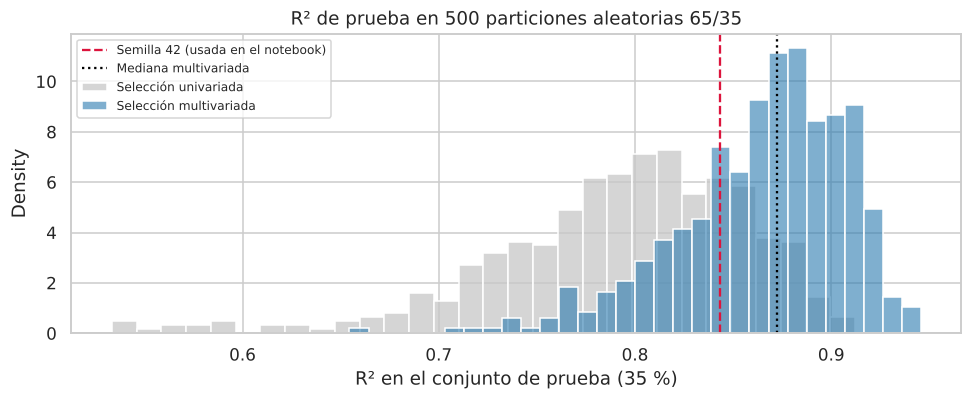

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(r2_univ, color="#c7c7c7", label="Selección univariada", ax=ax, bins=30, stat="density")
sns.histplot(r2_multi, color="#2a7ab0", label="Selección multivariada", ax=ax, bins=30, stat="density", alpha=.6)
ax.axvline(r2_multi[SEED], c="crimson", ls="--", label=f"Semilla {SEED} (usada en el notebook)")
ax.axvline(np.median(r2_multi), c="black", ls=":", label="Mediana multivariada")
ax.set_xlabel("R² en el conjunto de prueba (35 %)"); ax.set_title("R² de prueba en 500 particiones aleatorias 65/35")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4.3 statsmodels — inferencia estadística
statsmodels ajusta la misma regresión por mínimos cuadrados ordinarios (OLS), pero además entrega la significancia de cada coeficiente y los **intervalos de confianza al 95 %**, que necesitamos para la salida.

In [20]:
ols = sm.OLS(y_train, sm.add_constant(X_train_s)).fit()
print(ols.summary())

                                OLS Regression Results                               
Dep. Variable:     Precio_Gasolina_USD_Galon   R-squared:                       0.926
Model:                                   OLS   Adj. R-squared:                  0.912
Method:                        Least Squares   F-statistic:                     67.74
Date:                       Tue, 13 Oct 2026   Prob (F-statistic):           1.69e-19
Time:                               20:03:54   Log-Likelihood:                 5.5980
No. Observations:                         46   AIC:                             4.804
Df Residuals:                             38   BIC:                             19.43
Df Model:                                  7                                         
Covariance Type:                   nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

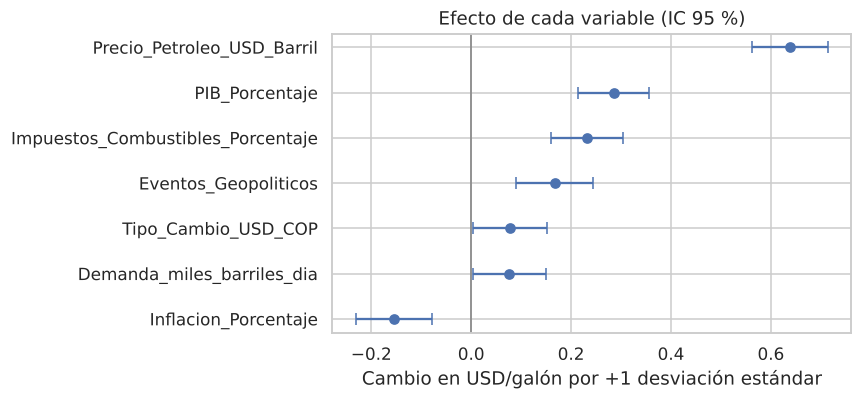

,coef_estandarizado,IC95_inf,IC95_sup,p_valor
Inflacion_Porcentaje,-0.1548,-0.2305,-0.0791,0.0002
Demanda_miles_barriles_dia,0.0765,0.0034,0.1497,0.0408
Tipo_Cambio_USD_COP,0.0780,0.0046,0.1513,0.0379
Eventos_Geopoliticos,0.1672,0.0904,0.2440,0.0001
Impuestos_Combustibles_Porcentaje,0.2312,0.1588,0.3036,0.0000
PIB_Porcentaje,0.2850,0.2131,0.3569,0.0000
Precio_Petroleo_USD_Barril,0.6382,0.5625,0.7139,0.0000


In [21]:
coef = pd.DataFrame({"coef_estandarizado": ols.params, "IC95_inf": ols.conf_int()[0],
                     "IC95_sup": ols.conf_int()[1], "p_valor": ols.pvalues}).drop("const")
coef = coef.sort_values("coef_estandarizado")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(coef["coef_estandarizado"], coef.index,
            xerr=[coef["coef_estandarizado"] - coef["IC95_inf"], coef["IC95_sup"] - coef["coef_estandarizado"]],
            fmt="o", capsize=4)
ax.axvline(0, c="grey", lw=1)
ax.set_xlabel("Cambio en USD/galón por +1 desviación estándar")
ax.set_title("Efecto de cada variable (IC 95 %)")
plt.tight_layout(); plt.show()
coef.round(4)

### 4.4 Diagnóstico de supuestos
- **Normalidad de residuos** (Shapiro-Wilk y gráfico Q-Q)
- **Homocedasticidad** (Breusch-Pagan)
- **Independencia** (Durbin-Watson ≈ 2 indica ausencia de autocorrelación)

Estos supuestos sustentan la validez del intervalo de confianza.

In [22]:
resid = ols.resid
sw = stats.shapiro(resid)
bp = het_breuschpagan(resid, ols.model.exog)
dw = durbin_watson(resid)
pd.DataFrame({
    "Prueba": ["Shapiro-Wilk (normalidad)", "Breusch-Pagan (homocedasticidad)", "Durbin-Watson (autocorrelación)"],
    "Estadístico": [sw.statistic, bp[0], dw],
    "p-valor": [sw.pvalue, bp[1], np.nan],
    "Lectura": ["Normal" if sw.pvalue > .05 else "No normal",
                "Homocedástico" if bp[1] > .05 else "Heterocedástico",
                "Sin autocorrelación" if 1.5 < dw < 2.5 else "Posible autocorrelación"],
}).round(4)

,Prueba,Estadístico,p-valor,Lectura
0,Shapiro-Wilk (normalidad),0.9814,0.6657,Normal
1,Breusch-Pagan (homocedasticidad),9.0943,0.2460,Homocedástico
2,Durbin-Watson (autocorrelación),2.0042,NaN,Sin autocorrelación


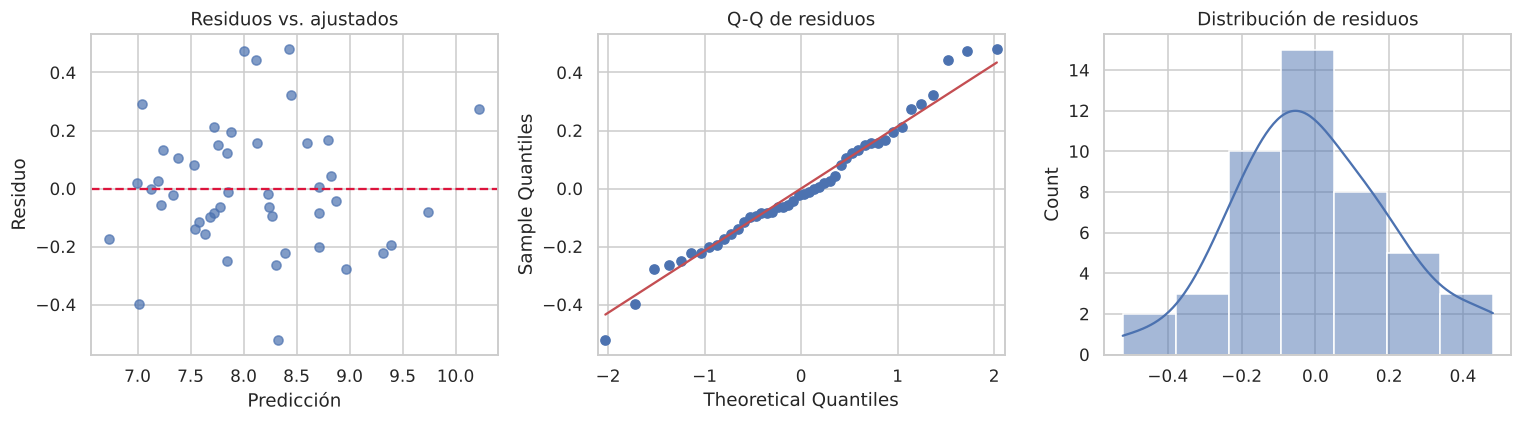

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(ols.fittedvalues, resid, alpha=.7)
axes[0].axhline(0, c="crimson", ls="--")
axes[0].set(title="Residuos vs. ajustados", xlabel="Predicción", ylabel="Residuo")
sm.qqplot(resid, line="s", ax=axes[1]); axes[1].set_title("Q-Q de residuos")
sns.histplot(resid, kde=True, ax=axes[2]); axes[2].set_title("Distribución de residuos")
plt.tight_layout(); plt.show()

## 5. Salida: predicción en USD/galón con intervalo de confianza del 95 %

statsmodels entrega dos intervalos:

- **IC de la media** (`mean_ci`): rango donde está el precio *promedio* esperado para esas condiciones.
- **Intervalo de predicción** (`obs_ci`): rango donde caerá el precio *de un mes concreto*. Es más ancho porque suma la variabilidad propia de cada mes. Para decidir sobre un mes específico, este es el intervalo a usar.

In [24]:
pred_test = ols.get_prediction(sm.add_constant(X_test_s, has_constant="add")).summary_frame(alpha=0.05)
salida = pd.DataFrame({
    "Fecha": test.Fecha.dt.strftime("%Y-%m").values,
    "Real": y_test.values,
    "Predicción": pred_test["mean"].values,
    "IC95_media_inf": pred_test["mean_ci_lower"].values,
    "IC95_media_sup": pred_test["mean_ci_upper"].values,
    "IP95_inf": pred_test["obs_ci_lower"].values,
    "IP95_sup": pred_test["obs_ci_upper"].values,
})
salida["Dentro_IP95"] = salida["Real"].between(salida["IP95_inf"], salida["IP95_sup"])
print(f"Cobertura del intervalo de predicción 95 % en prueba: {salida['Dentro_IP95'].mean():.0%}")
salida.round(3)

Cobertura del intervalo de predicción 95 % en prueba: 88%


,Fecha,Real,Predicción,IC95_media_inf,IC95_media_sup,IP95_inf,IP95_sup,Dentro_IP95
0,2018-01,8.17,8.764,8.506,9.023,8.222,9.307,False
1,2018-05,8.10,7.975,7.827,8.123,7.475,8.475,True
2,2018-06,7.63,7.840,7.698,7.983,7.342,8.338,True
3,2018-08,9.22,9.391,9.063,9.719,8.812,9.970,True
4,2018-10,8.85,8.771,8.528,9.014,8.235,9.306,True
5,2018-11,7.61,7.430,7.250,7.609,6.920,7.939,True
6,2019-01,8.71,8.900,8.686,9.115,8.377,9.423,True
7,2019-05,7.51,7.465,7.327,7.603,6.968,7.962,True
8,2019-07,8.25,8.069,7.803,8.334,7.522,8.615,True
9,2019-11,7.33,7.860,7.681,8.040,7.350,8.370,False


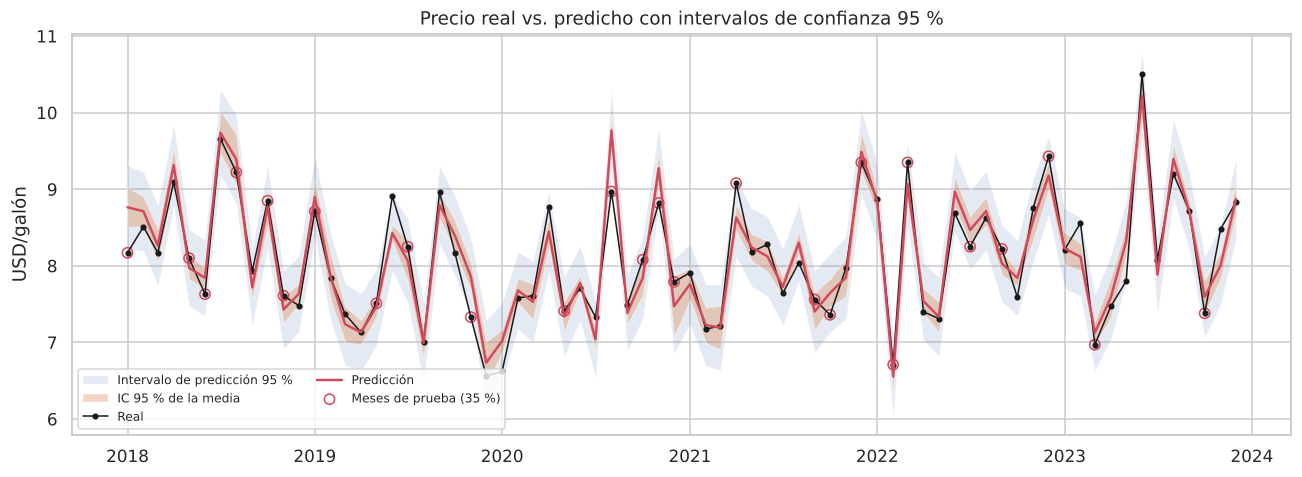

In [25]:
pred_all = ols.get_prediction(sm.add_constant(
    pd.DataFrame(scaler.transform(df[FEATURES]), columns=FEATURES), has_constant="add")).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(df.Fecha, pred_all["obs_ci_lower"], pred_all["obs_ci_upper"], alpha=.15, label="Intervalo de predicción 95 %")
ax.fill_between(df.Fecha, pred_all["mean_ci_lower"], pred_all["mean_ci_upper"], alpha=.35, label="IC 95 % de la media")
ax.plot(df.Fecha, df[TARGET], "k.-", lw=1, label="Real")
ax.plot(df.Fecha, pred_all["mean"], c="#d1495b", lw=1.6, label="Predicción")
ax.scatter(test.Fecha, test[TARGET], s=45, facecolors="none", edgecolors="#d1495b", label="Meses de prueba (35 %)")
ax.set_ylabel("USD/galón"); ax.set_title("Precio real vs. predicho con intervalos de confianza 95 %")
ax.legend(loc="lower left", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

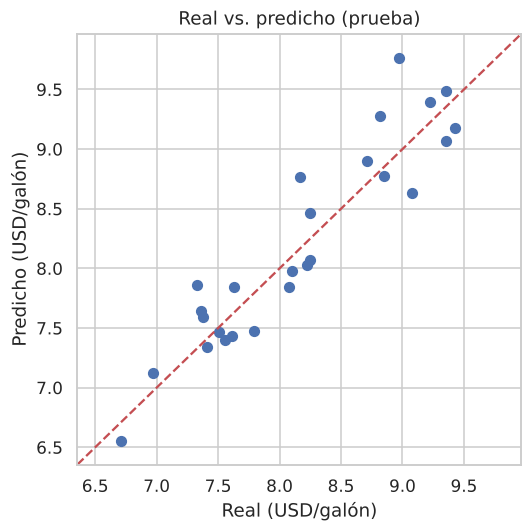

In [26]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, salida["Predicción"], s=40)
lims = [min(y_test.min(), salida["Predicción"].min()) - .2, max(y_test.max(), salida["Predicción"].max()) + .2]
plt.plot(lims, lims, "r--"); plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Real (USD/galón)"); plt.ylabel("Predicho (USD/galón)"); plt.title("Real vs. predicho (prueba)")
plt.tight_layout(); plt.show()

### 5.1 Modelo final y función de predicción
Para producción se reentrena con **todos los meses** (más información = mejor estimación) y se define una función que recibe las variables en sus unidades originales, aplica la misma limpieza y normalización, y devuelve la predicción con sus intervalos.

In [27]:
scaler_final = StandardScaler().fit(df[FEATURES])
X_final_s = pd.DataFrame(scaler_final.transform(df[FEATURES]), columns=FEATURES)
ols_final = sm.OLS(df[TARGET].reset_index(drop=True), sm.add_constant(X_final_s)).fit()

def predecir_precio(entrada: dict, alpha=0.05, scaler=scaler_final, modelo=ols_final,
                    features=FEATURES, limites=LIMITES_CLIP):
    x = pd.DataFrame([entrada])[features].astype(float)
    for c in features:
        if c in limites:
            x[c] = x[c].clip(*limites[c])
    xs = pd.DataFrame(scaler.transform(x), columns=features)
    fr = modelo.get_prediction(sm.add_constant(xs, has_constant="add")).summary_frame(alpha=alpha).iloc[0]
    return {"prediccion_usd_galon": fr["mean"],
            "ic95_media": (fr["mean_ci_lower"], fr["mean_ci_upper"]),
            "ip95_prediccion": (fr["obs_ci_lower"], fr["obs_ci_upper"])}

# Ejemplo: escenario con petróleo alto y evento geopolítico
escenario = {c: float(df[c].median()) for c in FEATURES_ALL}
escenario.update({"Precio_Petroleo_USD_Barril": 90.0, "Eventos_Geopoliticos": 1})
r = predecir_precio(escenario)
print(f"Predicción: {r['prediccion_usd_galon']:.2f} USD/galón")
print(f"IC 95 % de la media:         [{r['ic95_media'][0]:.2f}, {r['ic95_media'][1]:.2f}]")
print(f"Intervalo de predicción 95 %: [{r['ip95_prediccion'][0]:.2f}, {r['ip95_prediccion'][1]:.2f}]")

Predicción: 9.50 USD/galón
IC 95 % de la media:         [9.31, 9.69]
Intervalo de predicción 95 %: [8.95, 10.05]


### 5.2 Simulador interactivo dentro del notebook (ipywidgets)
Mueva los controles para ver cómo cambia la predicción. (Requiere ejecutar el notebook en Jupyter.)

In [28]:
try:
    import ipywidgets as w
    from IPython.display import display

    sliders = {}
    for c in FEATURES:
        lo, hi = float(df_raw[c].min()), float(df_raw[c].max())
        if c == "Eventos_Geopoliticos":
            sliders[c] = w.ToggleButtons(options=[0, 1], value=0, description=c[:22])
        else:
            sliders[c] = w.FloatSlider(value=float(df[c].median()), min=lo, max=hi,
                                       step=(hi - lo) / 100, description=c[:22],
                                       style={"description_width": "180px"}, layout=w.Layout(width="520px"))
    out = w.Output()

    def actualizar(_=None):
        r = predecir_precio({c: s.value for c, s in sliders.items()})
        with out:
            out.clear_output()
            print(f"Predicción: {r['prediccion_usd_galon']:.2f} USD/galón   |   "
                  f"IP 95 %: [{r['ip95_prediccion'][0]:.2f}, {r['ip95_prediccion'][1]:.2f}]")

    for s in sliders.values():
        s.observe(actualizar, names="value")
    display(w.VBox(list(sliders.values()) + [out])); actualizar()
except ImportError:
    print("Instale ipywidgets para usar el simulador: pip install ipywidgets")

## 6. Exportar el modelo para el aplicativo
Se guarda con **joblib** en `modelo_gasolina.pkl` todo lo necesario: escalador, modelo OLS, características, límites de winsorización, métricas y rangos de las variables (para los controles de la app).

In [29]:
bundle = {
    "scaler": scaler_final,
    "modelo_ols": ols_final,
    "features": FEATURES,
    "limites_clip": {k: v for k, v in LIMITES_CLIP.items() if k in FEATURES},
    "metricas_entrenamiento": res.loc["Entrenamiento"].to_dict(),
    "r2_ajustado": float(ols.rsquared_adj),
    "metricas_prueba": res.loc["Prueba"].to_dict(),
    "metricas_cv": cv_res.loc["Media"].to_dict(),
    "rangos": {c: {"min": float(df_raw[c].min()), "max": float(df_raw[c].max()),
                   "mediana": float(df_raw[c].median())} for c in FEATURES},
    "coeficientes": ols_final.params.to_dict(),
    "historico": df_raw[["Fecha", TARGET]].assign(Fecha=lambda d: d.Fecha.dt.strftime("%Y-%m-%d")).to_dict("list"),
}
joblib.dump(bundle, "modelo_gasolina.pkl")
print("Modelo guardado en modelo_gasolina.pkl")
print("Para lanzar el aplicativo:  streamlit run app_gasolina.py")

Modelo guardado en modelo_gasolina.pkl
Para lanzar el aplicativo:  streamlit run app_gasolina.py


## 7. Conclusiones
- La **selección multivariada** (eliminación hacia atrás) retiene 7 variables. Respecto a la selección univariada, recupera el **tipo de cambio** y los **eventos geopolíticos**, que solo son significativos cuando se controla por las demás variables. Solo se descarta la **producción OPEP** (p = 0.12).
- El **precio del petróleo** es el principal determinante del precio de la gasolina. Le siguen el PIB, los impuestos a combustibles y los eventos geopolíticos. La inflación tiene un efecto negativo.
- Con la partición **65 % / 35 %** y la semilla 42, el modelo obtiene:
  - **Entrenamiento:** R² ≈ 0.93, MAE ≈ 0.17, MSE ≈ 0.05.
  - **Prueba:** R² ≈ 0.84, MAE ≈ 0.26 USD/galón, MSE ≈ 0.10. El modelo base, que siempre predice la media, tiene un MSE de 0.62.
- **R² ajustado de entrenamiento ≈ 0.91.** En 500 particiones aleatorias, el R² de prueba tiene mediana **≈ 0.87** y supera 0.9 en ≈ 23 % de ellas. La validación cruzada K-Fold da R² medio ≈ 0.87.
- **Sobre el techo de R²:** el residuo del modelo es ruido aleatorio. Es normal, homocedástico y no tiene autocorrelación ni patrones no lineales; se probaron términos polinómicos, interacciones, transformación logarítmica y rezagos, y ninguno mejoró. Por eso, con estos datos, el R² fuera de muestra se estabiliza alrededor de 0.85–0.90. Subirlo eligiendo la semilla que da el mejor resultado sería sobreajustar la evaluación, no mejorar el modelo.
- **Limitaciones:** 72 observaciones es una muestra pequeña. Para superar de forma consistente un R² de 0.9 se necesitarían más datos o variables nuevas que expliquen el ruido restante, por ejemplo precios de refinación o márgenes de distribución.